# 03 · Honest evaluation, classical models and feature work (Track A)
All numbers come from `experiments/run_track_a.py` (saved in `results/track_a/`). Re-run it to regenerate them; this notebook only loads and explains. Noise floor (from the paper) = MSE 0.0025.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.precision', 4)
from IPython.display import Image, display
R, F = '../results/track_a/', '../results/figures/'
# !cd .. && python experiments/run_track_a.py   # ~10 min

## E1a · Reproducing the Lasso half of Table I (protocol P1, random k-fold)
The paper text says 10-fold, but their code uses 5, so both are shown.

In [2]:
e1 = pd.read_csv(R + 'e1_table1_lasso.csv')
e1.pivot_table(index='features', columns=['subject', 'folds'], values=['mse', 'paper']).round(4)

mse                           paper                        
subject       S1              S2              S1              S2        
folds         5       10      5       10      5       10      5       10
features                                                                
Mean      0.0664  0.0665  0.0363  0.0363  0.0657  0.0657  0.0465  0.0465
all       0.0104  0.0099  0.0138  0.0134  0.0089  0.0089  0.0176  0.0176
emg       0.0166  0.0166  0.0180  0.0177  0.0158  0.0158  0.0203  0.0203
step      0.0213  0.0211  0.0203  0.0200  0.0200  0.0200  0.0217  0.0217
step+emg  0.0107  0.0103  0.0143  0.0143  0.0089  0.0089  0.0168  0.0168

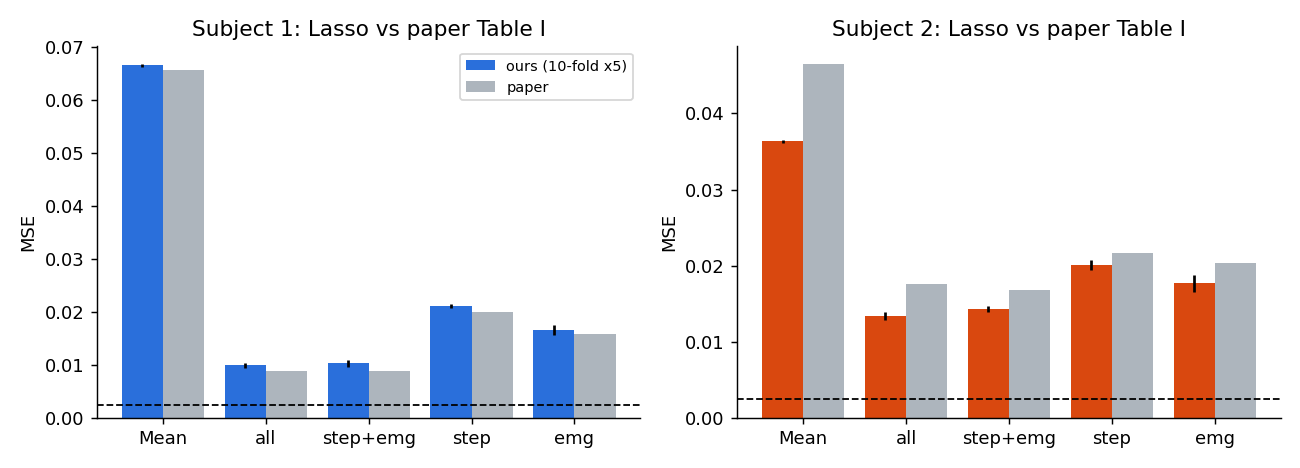

In [3]:
display(Image(F + 'e1_table1_lasso.png'))

## E2 · Random k-fold (P1) vs leave-one-day-out (P2)
Same models, same data. Only the split changes.

In [4]:
e2 = pd.read_csv(R + 'e2_kfold_vs_lodo.csv'); e2[e2.features == 'all'].pivot_table(index='model', columns=['subject', 'protocol'], values='mse')

subject            S1              S2        
protocol        kfold    lodo   kfold    lodo
model                                        
ARD            0.0109  0.0235  0.0138  0.0297
BayesianRidge  0.0089  0.0136  0.0145  0.0454
ElasticNet     0.0097  0.0192  0.0136  0.0264
GP             0.0079  0.0249  0.0126  0.0356
KernelRidge    0.0098  0.0315  0.0141  0.0406
Lasso          0.0099  0.0226  0.0134  0.0266
Mean           0.0665  0.0917  0.0363  0.0478
PLS            0.0092  0.0145  0.0155  0.0477
Ridge          0.0089  0.0143  0.0164  0.0358
SVR            0.0109  0.0432  0.0143  0.0593

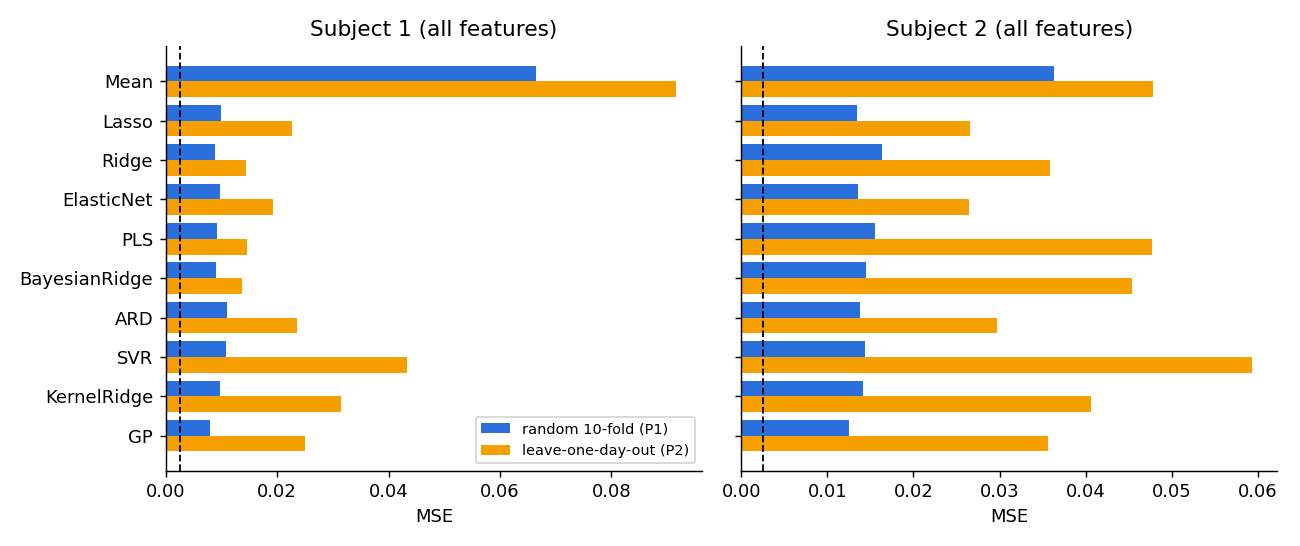

In [5]:
display(Image(F + 'e2_kfold_vs_lodo.png'))

## E3a · Tuned with nested LODO (P3): honest leaderboard
The inner loop tunes hyperparameters on the 4 training days only. `spearman_day` and `top5_in_top10` measure whether the model ranks the 36 settings within an unseen day correctly, which is what HILO actually needs.

In [6]:
e3 = pd.read_csv(R + 'e3_nested_lodo_leaderboard.csv'); e3.sort_values(['subject', 'features', 'mse']).groupby(['subject', 'features']).head(10)

,model,subject,features,mse,mse_std,r2,skill,spearman_day,top5_in_top10
20,BayesianRidge,S1,all,0.0136,0.0032,0.7925,0.8512,0.6184,0.52
8,Ridge,S1,all,0.0143,0.0035,0.7819,0.8436,0.6094,0.60
16,PLS,S1,all,0.0159,0.0045,0.7585,0.8268,0.6097,0.56
12,ElasticNet,S1,all,0.0193,0.0109,0.7062,0.7893,0.5935,0.56
4,Lasso,S1,all,0.0199,0.0116,0.6975,0.7831,0.5884,0.56
32,KernelRidge,S1,all,0.0204,0.0092,0.6891,0.7771,0.5657,0.52
28,SVR,S1,all,0.0225,0.0143,0.6571,0.7541,0.5290,0.52
24,ARD,S1,all,0.0235,0.0061,0.6422,0.7434,0.5620,0.52
36,GP,S1,all,0.0249,0.0189,0.6209,0.7281,0.5384,0.52
0,Mean,S1,all,0.0917,0.0486,-0.3944,0.0000,NaN,NaN


In [7]:
pd.read_csv(R + 'e3_forward_chaining.csv')  # P5: train on days 1..k, test day k+1

,model,subject,mse,skill,spearman_day
0,Mean,S1,0.1239,0.0000,NaN
1,Mean,S2,0.0537,0.0000,NaN
2,Lasso,S1,0.0254,0.7948,0.5753
3,Lasso,S2,0.0945,-0.7602,0.0683
4,Ridge,S1,0.0271,0.7817,0.5671
5,Ridge,S2,0.0702,-0.3081,-0.0481
6,BayesianRidge,S1,0.0248,0.7997,0.5617
7,BayesianRidge,S2,0.0857,-0.5975,-0.0060
8,PLS,S1,0.0283,0.7718,0.5659
9,PLS,S2,0.0796,-0.4828,-0.0051


## E5 · Feature reduction: the paper's PCA / forward selection vs target-aware methods
All selectors are fit inside each training fold. Downstream model: Ridge. Base set: step + EMG (25 features).

In [8]:
pd.read_csv(R + 'e5_feature_selection_best.csv')

,method,S1_kfold,S1_lodo,S2_kfold,S2_lodo
0,ard,0.0105,0.0203,0.0154,0.0410
1,forward,0.0097,0.0166,0.0149,0.0437
2,mi,0.0101,0.0190,0.0137,0.0365
3,none (all 25),0.0097,0.0167,0.0150,0.0472
4,pca,0.0097,0.0167,0.0134,0.0444
5,pls,0.0097,0.0156,0.0138,0.0458
6,rfe,0.0097,0.0165,0.0148,0.0294
7,stability,0.0103,0.0294,0.0129,0.0328


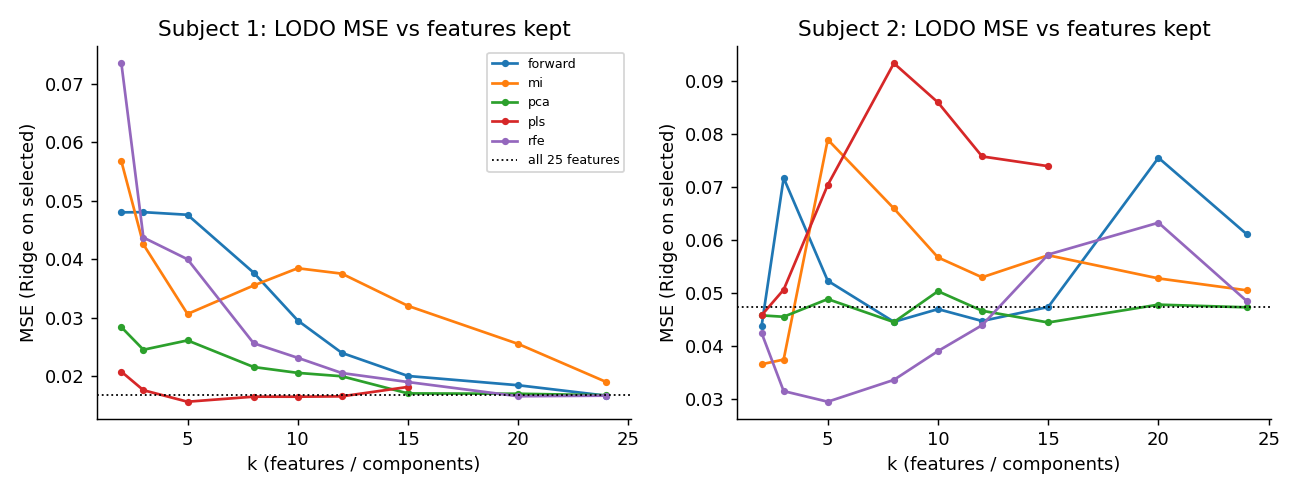

,subject,method,k,features
0,S1,forward,10.0,"L_peak_pf, R_step_time, emg3, emg7, emg8, emg9..."
1,S1,mi,10.0,"L_peak_pf, L_step_time, R_peak_pf, R_step_time..."
2,S1,rfe,10.0,"L_peak_pf, R_peak_df, emg3, emg5, emg6, emg8, ..."
3,S1,stability,NaN,"L_peak_df, L_peak_pf, R_step_time, emg2, emg3,..."
4,S1,ard,NaN,"L_peak_pf, R_peak_df, R_step_time, step_width,..."
5,S2,forward,10.0,"L_peak_pf, L_step_time, R_peak_pf, R_step_time..."
6,S2,mi,10.0,"L_peak_df, L_peak_pf, R_peak_pf, step_width, e..."
7,S2,rfe,10.0,"L_peak_pf, L_step_time, R_step_time, emg2, emg..."
8,S2,stability,NaN,"L_peak_df, L_peak_pf, R_peak_pf, emg2, emg4, e..."
9,S2,ard,NaN,"L_peak_df, L_peak_pf, R_peak_pf, emg2, emg4, e..."


In [9]:
display(Image(F + 'e5_feature_selection.png'))
pd.read_csv(R + 'e5_selected_features.csv')

## E6 · Feature-engineering ablation

In [10]:
pd.read_csv(R + 'e6_feature_engineering_ablation.csv')

,variant,model,S1_kfold,S1_lodo,S2_kfold,S2_lodo
0,+all three,BayesianRidge,0.0097,0.0162,0.0146,0.0623
1,+all three,Lasso,0.0109,0.0251,0.0148,0.0343
2,+all three,Ridge,0.0101,0.0164,0.0140,0.0428
3,+emg_bilateral,BayesianRidge,0.0097,0.0161,0.0147,0.0632
4,+emg_bilateral,Lasso,0.0103,0.0239,0.0146,0.0348
5,+emg_bilateral,Ridge,0.0097,0.0169,0.0142,0.0455
6,+emg_summary,BayesianRidge,0.0097,0.0159,0.0147,0.0626
7,+emg_summary,Lasso,0.0106,0.0251,0.0144,0.0351
8,+emg_summary,Ridge,0.0098,0.0164,0.0141,0.0465
9,+interactions (top 3),Ridge,0.0095,0.0174,0.0137,0.0662


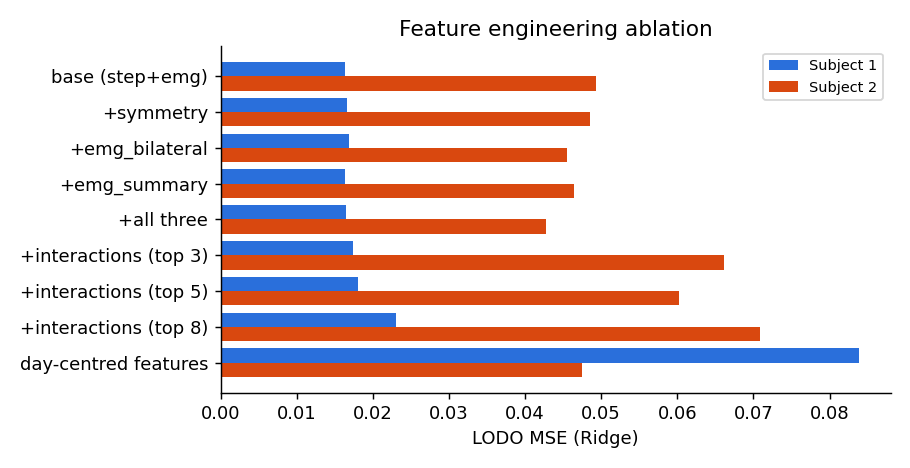

In [11]:
display(Image(F + 'e6_feature_engineering.png'))

## E7a · Cross-subject (P4) and time-only baseline

In [12]:
e7 = pd.read_csv(R + 'e7_cross_subject.csv'); e7.pivot_table(index='model', columns=['train', 'test', 'features'], values='mse')

train              S1                       S2                 
test               S2                       S1                 
features          emg    step step+emg     emg    step step+emg
model                                                          
BayesianRidge  0.6163  0.0855   0.1807  0.0525  0.0659   0.0415
GP             0.0705  0.2290   0.0733  0.0533  0.0670   0.0536
Lasso          0.4952  0.0637   0.1947  0.0514  0.0595   0.0458
Mean           0.0358  0.0358   0.0358  0.0658  0.0658   0.0658
PLS            0.2968  0.0856   0.1556  0.0527  0.0764   0.0469
Ridge          0.3928  0.0867   0.1554  0.0495  0.0683   0.0471
SVR            0.0493  0.1622   0.0482  0.0679  0.0880   0.0826

,subject,time_feature,protocol,mse,mean_mse,skill
0,S1,position within day,kfold,0.0628,0.0665,5.4754e-02
1,S1,position within day,lodo,0.0874,0.0917,4.6373e-02
2,S1,global time index,kfold,0.0167,0.0665,7.4943e-01
3,S1,global time index,lodo,0.0373,0.0917,5.9292e-01
4,S1,(reference) Ridge on all sensors,kfold,0.0089,0.0665,8.6653e-01
5,S1,(reference) Ridge on all sensors,lodo,0.0143,0.0917,8.4377e-01
6,S2,position within day,kfold,0.0364,0.0363,-3.0774e-03
7,S2,position within day,lodo,0.0478,0.0478,-6.4387e-05
8,S2,global time index,kfold,0.0149,0.0363,5.8861e-01
9,S2,global time index,lodo,0.0205,0.0478,5.7168e-01


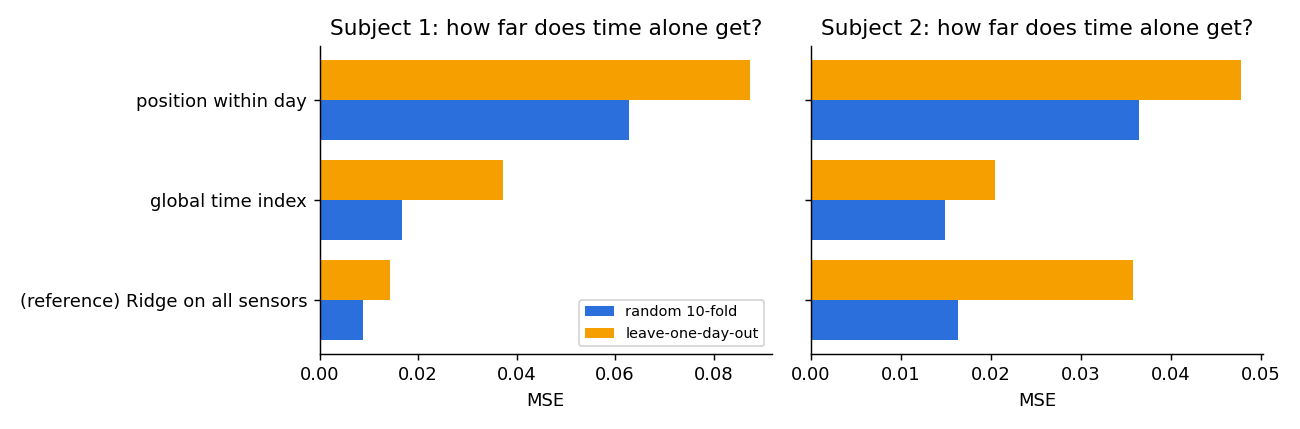

In [13]:
display(pd.read_csv(R + 'e7_time_only_baseline.csv')); display(Image(F + 'e7_time_only_baseline.png'))

## Findings (Track A)
See the auto-generated summary below. It's written from the CSVs, so it stays in sync with the numbers.

In [14]:
e2a = e2[e2.features == 'all'].pivot_table(index=['subject', 'model'], columns='protocol', values='mse')
gap = (e2a['lodo'] / e2a['kfold']).groupby('subject').median()
best = e3.loc[e3.groupby('subject').mse.idxmin(), ['subject', 'model', 'features', 'mse', 'skill', 'spearman_day']]
tb = pd.read_csv(R + 'e7_time_only_baseline.csv')
print('Median LODO / k-fold MSE ratio:', gap.round(2).to_dict())
print('Best nested-LODO classical model per subject:'); print(best.to_string(index=False))
print('Time-index-only baseline, LODO MSE:', tb[(tb.time_feature == 'global time index') & (tb.protocol == 'lodo')].set_index('subject').mse.round(4).to_dict())

Median LODO / k-fold MSE ratio: {'S1': 2.07, 'S2': 2.51}
Best nested-LODO classical model per subject:
subject         model features    mse  skill  spearman_day
     S1 BayesianRidge      all 0.0136 0.8512        0.6184
     S2    ElasticNet      all 0.0252 0.4741        0.3655
Time-index-only baseline, LODO MSE: {'S1': 0.0373, 'S2': 0.0205}
